# 12 — Operator backpropagation with `qiskit-addon-obp`

**Operator backpropagation (OBP)** ([IBM Quantum guide](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-addon-obp) [9]) makes a quantum circuit shorter. It removes the last layers of the circuit and moves them
into the observable. A classical computer does this part of the calculation. The quantum computer then runs a
**shallower circuit** and measures a **modified observable**. The expectation value does not change.

* Benefit: shallower circuits collect less hardware noise.
* Cost: the new observable has more Pauli terms. This means more measurement groups and more shots.
* Control of the cost: OBP can **truncate** (remove) Pauli terms with small coefficients. Truncation adds an error with a
  rigorous upper bound.

The `qiskit-addon-obp` package (version 0.3.0 here) provides:

| object | purpose | API page |
|---|---|---|
| `qiskit_addon_obp.backpropagate(observables, slices, truncation_error_budget=..., operator_budget=..., max_seconds=...)` | the main routine | [4](https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.html) |
| `qiskit_addon_obp.utils.simplify.OperatorBudget` | limits the size of the observable (`max_paulis`, `max_qwc_groups`) | [5](https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.utils.simplify.html) |
| `qiskit_addon_obp.utils.truncating.setup_budget` | limits the truncation error (per slice, in total, Lp norm) | [6](https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.utils.truncating.html) |
| `qiskit_addon_obp.utils.metadata.OBPMetadata` | records each step, including the accumulated error bound | [7](https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.utils.metadata.html) |
| `qiskit_addon_obp.utils.visualization` | plots of the metadata | [8](https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.utils.visualization.html) |

The package works together with `qiskit-addon-utils`. That package builds the Hamiltonian and the Trotter circuit
([problem generators](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.problem_generators.html) [11]), and it cuts the circuit into *slices* ([slicing](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.slicing.html) [12]).

**Based on**

* [Tutorial: Reducing depth of circuits with operator backpropagation](https://qiskit.github.io/qiskit-addon-obp/tutorials/01_getting_started.html) [1] (Sections 2–6 follow it)
* [How-to: Truncating Pauli terms during backpropagation](https://qiskit.github.io/qiskit-addon-obp/how_tos/truncate_operator_terms.html) [2] (Section 5)
* [How-to: Using different Lp-norms for Pauli term truncation](https://qiskit.github.io/qiskit-addon-obp/how_tos/bound_error_using_p_norm.html) [3] (Section 1)
* IBM Quantum documentation: [Operator backpropagation](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-addon-obp) [9] and its [Quick start](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-addon-obp/guides/quickstart) [10]

The parameter sweeps (Sections 7–8) and the noisy simulation (Section 9) are our own additions.

Install:

```bash
pip install qiskit-addon-obp
```

**Contents**

1. Theory: the Heisenberg picture and backpropagation
2. The problem: a 10-qubit Heisenberg XYZ chain and its Trotter circuit
3. Slicing the circuit
4. Backpropagation without truncation (operator budget only)
5. Backpropagation with truncation (error budget)
6. Evaluating the reduced experiments with `StatevectorEstimator`
7. Sweep: error budget vs. depth reduction vs. accuracy
8. The operator budget trade-off
9. Noisy simulation with Aer and a fake backend
10. Summary, notes on the installed version, references

## 1. Theory: the Heisenberg picture and backpropagation

We want the expectation value
$$
\langle O\rangle = \langle 0|\,U^\dagger\, O\, U\,|0\rangle,\qquad U = U_L\,U_{L-1}\cdots U_1 .
$$
The circuit $U$ is cut into $L$ **slices** $U_1,\dots,U_L$. Each slice is a layer of gates on all qubits.

* In the **Schrödinger picture**, the *state* evolves, $|\psi\rangle = U|0\rangle$, and the observable is fixed. A quantum computer works in this picture.
* In the **Heisenberg picture**, the *observable* evolves, $O \mapsto U^\dagger O U$, and the state stays $|0\rangle$.

Both pictures give the same number. OBP **combines the two pictures**. It evolves the observable backwards through the last $k$ slices on a classical computer,
$$
O_k = U_{L-k+1}^\dagger\cdots U_L^\dagger\; O\; U_L\cdots U_{L-k+1},
$$
and leaves only the first $L-k$ slices for the quantum computer:
$$
\langle O\rangle = \langle 0|\,(U_{L-k}\cdots U_1)^\dagger\; O_k\; (U_{L-k}\cdots U_1)\,|0\rangle .
$$

**Classical cost for a few slices.** Write $O=\sum_P c_P P$ as a sum of Pauli strings. Conjugation of a Pauli $P$
by a rotation $e^{-i\theta Q/2}$ gives
$$
e^{i\theta Q/2}\,P\,e^{-i\theta Q/2} =
\begin{cases} P & [P,Q]=0\\ \cos\theta\,P + i\sin\theta\, QP & \{P,Q\}=0 .\end{cases}
$$
Each anticommuting Pauli rotation can therefore at most **double** the number of terms. Locality limits the growth further:
only gates inside the **light cone** of the observable matter. Gates outside the light cone of $O$ are absorbed at no cost.

**Truncation.** After each slice, OBP may remove terms with small $|c_P|$. Let $T$ be the set of removed terms, with coefficients $\{c_P\}_{P\in T}$.
The error in the expectation value then has the bound
$$
\bigl|\langle O_k\rangle - \langle \tilde O_k\rangle\bigr| \le \sum_{P\in T}|c_P|\;\cdot\;\max_P |\langle P\rangle| \le \|c_T\|_1 ,
$$
because $|\langle P\rangle|\le 1$ for every Pauli string. Unitary conjugation keeps this bound through the remaining slices, so the
errors of the single slices add up. `OBPMetadata.accumulated_error(...)` returns this sum. Higher Lp norms (`p_norm`) give tighter
estimates, but these estimates are not strict bounds (see the [how-to guide on Lp norms](https://qiskit.github.io/qiskit-addon-obp/how_tos/bound_error_using_p_norm.html) [3]).

**Stopping criteria.** Backpropagation stops in two cases:

* the next slice would make the observable exceed the `OperatorBudget`, for example more than `max_qwc_groups`
  qubit-wise commuting (QWC) measurement groups (each group needs its own set of shots);
* all slices are absorbed.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.synthesis import LieTrotter
from qiskit.transpiler import CouplingMap, generate_preset_pass_manager
from qiskit.primitives import StatevectorEstimator

from qiskit_addon_utils.problem_generators import generate_xyz_hamiltonian, generate_time_evolution_circuit
from qiskit_addon_utils.slicing import slice_by_gate_types, combine_slices

from qiskit_addon_obp import backpropagate
from qiskit_addon_obp.utils.simplify import OperatorBudget
from qiskit_addon_obp.utils.truncating import setup_budget
from qiskit_addon_obp.utils import visualization as obp_vis

import qiskit, qiskit_aer
from importlib.metadata import version
print("qiskit", qiskit.__version__, "| qiskit-addon-obp", version("qiskit-addon-obp"),
      "| qiskit-addon-utils", version("qiskit-addon-utils"), "| qiskit-aer", qiskit_aer.__version__)
warnings.filterwarnings("ignore", category=DeprecationWarning)

qiskit 2.5.2 | qiskit-addon-obp 0.3.0 | qiskit-addon-utils 0.4.0 | qiskit-aer 0.17.2


## 2. The problem: a 10-qubit Heisenberg XYZ chain

As in the [tutorial](https://qiskit.github.io/qiskit-addon-obp/tutorials/01_getting_started.html) [1], we use an anisotropic Heisenberg (XYZ) model with a magnetic field on an open chain of 10 qubits:
$$
H=\sum_{\langle i,j\rangle}\bigl(J_x X_iX_j + J_y Y_iY_j + J_z Z_iZ_j\bigr) + \sum_i \bigl(h_x X_i + h_y Y_i + h_z Z_i\bigr),
$$
with $(J_x,J_y,J_z)=(\pi/8,\pi/4,\pi/2)$ and $(h_x,h_y,h_z)=(\pi/3,\pi/6,\pi/9)$.
The tutorial takes a 10-qubit line from a heavy-hex coupling map. `CouplingMap.from_line` gives the same chain.

`generate_xyz_hamiltonian` orders the terms by edge **color**. Terms on disjoint edges are therefore next to each other.
As a result, `generate_time_evolution_circuit` produces a circuit with compact layers.

In [2]:
N = 10
coupling_map = CouplingMap.from_line(N, bidirectional=False)

hamiltonian = generate_xyz_hamiltonian(
    coupling_map,
    coupling_constants=(np.pi / 8, np.pi / 4, np.pi / 2),
    ext_magnetic_field=(np.pi / 3, np.pi / 6, np.pi / 9),
)
print(f"{len(hamiltonian)} Pauli terms; first few:")
print(hamiltonian[:6])

57 Pauli terms; first few:
SparsePauliOp(['IIIIIIIXXI', 'IIIIIIIYYI', 'IIIIIIIZZI', 'IIIIIXXIII', 'IIIIIYYIII', 'IIIIIZZIII'],
              coeffs=[0.39269908+0.j, 0.78539816+0.j, 1.57079633+0.j, 0.39269908+0.j,
 0.78539816+0.j, 1.57079633+0.j])


We approximate $e^{-iHt}$ for $t=0.2$ with two first-order Lie–Trotter steps. The observable is $Z$ on qubit 0.
In Qiskit's little-endian Pauli labels, qubit 0 is the rightmost character.

gate counts: {'rx': 20, 'ry': 20, 'rz': 20, 'rxx': 18, 'ryy': 18, 'rzz': 18} | depth: 18


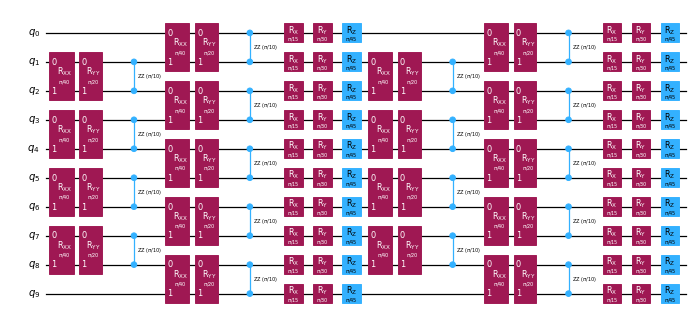

In [3]:
T_EVOL, REPS = 0.2, 2
circuit = generate_time_evolution_circuit(hamiltonian, time=T_EVOL, synthesis=LieTrotter(reps=REPS))
observable = SparsePauliOp("I" * (N - 1) + "Z")

print("gate counts:", dict(circuit.count_ops()), "| depth:", circuit.depth())
circuit.draw("mpl", fold=-1, scale=0.45)

**Reference value.** For 10 qubits, the *ideal* expectation value of the full Trotter circuit is a cheap statevector calculation.
In this notebook, "exact" means this number, and "error" means the deviation from it.
The Trotter error with respect to the true $e^{-iHt}$ is a separate quantity. OBP does not change it.

In [4]:
exact = Statevector(circuit).expectation_value(observable).real
print(f"exact <Z_0> of the full Trotter circuit: {exact:.10f}")

exact <Z_0> of the full Trotter circuit: 0.8854160688


## 3. Slicing the circuit

`backpropagate` takes a **list of slices**. Each slice is a `QuantumCircuit` on all qubits. The slices are absorbed **from the end**.
[`qiskit_addon_utils.slicing`](https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.slicing.html) [12] has several functions for slicing: `slice_by_gate_types`, `slice_by_depth`, `slice_by_barriers`
and `slice_by_coloring`. As in the tutorial, each slice here holds one gate type, for example a layer of `rx` or a layer of `rzz`
on even bonds. With finer slices, the stopping criterion can stop at a more precise point.

In [5]:
slices = slice_by_gate_types(circuit)
print(f"Separated the circuit into {len(slices)} slices:")
print([f"{s.data[0].operation.name}[{len(s.data)}]" for s in slices])

Separated the circuit into 18 slices:
['rxx[4]', 'ryy[4]', 'rzz[4]', 'rxx[5]', 'ryy[5]', 'rzz[5]', 'rx[10]', 'ry[10]', 'rz[10]', 'rxx[4]', 'ryy[4]', 'rzz[4]', 'rxx[5]', 'ryy[5]', 'rzz[5]', 'rx[10]', 'ry[10]', 'rz[10]']


## 4. Backpropagation with only an operator budget

First we backpropagate **without truncation**. The only limit is `OperatorBudget(max_qwc_groups=8)`: backpropagation stops before
the observable needs more than 8 QWC measurement groups. `backpropagate` returns three objects:

1. the new observable (one `SparsePauliOp` for one input observable, a list for a list);
2. the slices that were **not** absorbed; `combine_slices` joins them into a circuit;
3. an `OBPMetadata` object.

In [6]:
op_budget = OperatorBudget(max_qwc_groups=8)

t0 = time.perf_counter()
bp_obs, remaining_slices, metadata = backpropagate(observable, slices, operator_budget=op_budget)
print(f"backpropagate took {time.perf_counter() - t0:.3f} s")

bp_circuit = combine_slices(remaining_slices, include_barriers=True)

print(f"Backpropagated {metadata.num_backpropagated_slices} of {len(slices)} slices.")
print(f"New observable: {len(bp_obs)} terms in {len(bp_obs.group_commuting(qubit_wise=True))} QWC groups.")
last = metadata.backpropagation_history[-1]
print(f"One more slice would have given {last.num_paulis[0]} terms in {last.num_qwc_groups} QWC groups -> rejected.")
print(f"Depth: {circuit.depth()} -> {bp_circuit.depth(lambda x: x.operation.name != 'barrier')}")

backpropagate took 0.011 s
Backpropagated 7 of 18 slices.
New observable: 18 terms in 8 QWC groups.
One more slice would have given 27 terms in 12 QWC groups -> rejected.
Depth: 18 -> 11


In [7]:
print(bp_obs)

SparsePauliOp(['IIIIIIIIIZ', 'IIIIIIIIXY', 'IIIIIIIZYY', 'IIIIIIIIYX', 'IIIIIIIZXX', 'IIIIIIIIZI', 'IIIIIIIIIY', 'IIIIIIIIXZ', 'IIIIIIIZYZ', 'IIIIIIIIZX', 'IIIIIIIIYI', 'IIIIIIIZXI', 'IIIIIIIIIX', 'IIIIIIIIXI', 'IIIIIIIZYI', 'IIIIIIIIYZ', 'IIIIIIIZXZ', 'IIIIIIIIZY'],
              coeffs=[ 0.95785069+0.00000000e+00j,  0.07169491+0.00000000e+00j,
 -0.02329509+0.00000000e+00j, -0.1442835 +0.00000000e+00j,
 -0.04688055+0.00000000e+00j,  0.01193973+0.00000000e+00j,
  0.19604634+0.00000000e+00j, -0.01467402+0.00000000e+00j,
  0.00476788+0.00000000e+00j,  0.06369932+0.00000000e+00j,
  0.00476788+0.00000000e+00j,  0.00154918+0.00000000e+00j,
 -0.09818854+0.00000000e+00j, -0.00480569+4.12455016e-19j,
  0.00156146-1.34014759e-19j, -0.01479039+2.06227508e-19j,
 -0.00480569+6.70073793e-20j,  0.03190339+0.00000000e+00j])


The single-qubit operator $Z_0$ has become a combination of low-weight Paulis near qubit 0. These qubits form its backward light cone.
The [metadata](https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.utils.metadata.html) [7] records the growth of the operator for each slice. `backpropagation_history` also contains the **rejected** last
attempt. For this reason, its last point lies above the budget line.

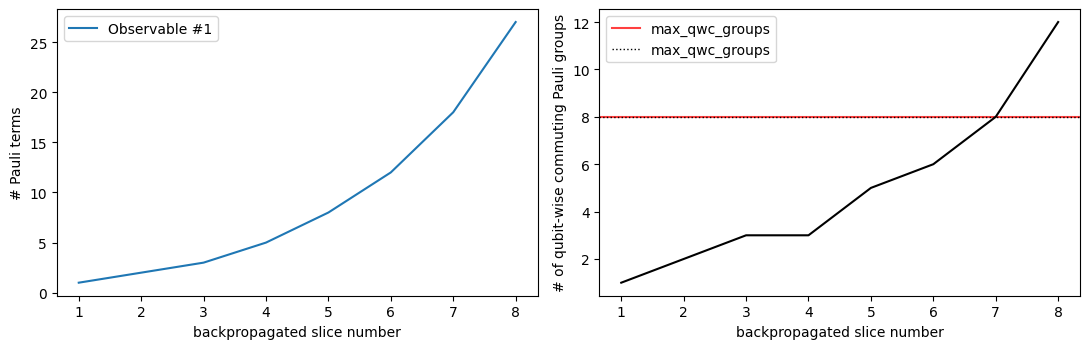

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
obp_vis.plot_num_paulis(metadata, axes[0])
obp_vis.plot_num_qwc_groups(metadata, axes[1])
axes[1].axhline(op_budget.max_qwc_groups, color="k", ls=":", lw=1, label="max_qwc_groups")
axes[1].legend()
fig.tight_layout()
plt.show()

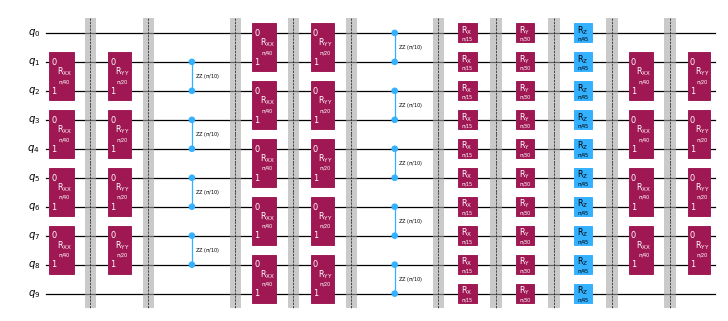

In [9]:
bp_circuit.draw("mpl", fold=-1, scale=0.45)

## 5. Backpropagation with a truncation error budget

Now we also allow truncation, as in the [how-to guide on truncation](https://qiskit.github.io/qiskit-addon-obp/how_tos/truncate_operator_terms.html) [2].
The call `setup_budget(max_error_per_slice=0.005)` ([API](https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.utils.truncating.html) [6]) allows each slice to remove Pauli terms whose coefficients
sum to at most $5\times10^{-3}$ in the L1 norm. **Budget that a slice does not use carries over** to later slices.

Options of `setup_budget`:

* `max_error_per_slice=ε` (float or list): the budget per slice;
* `max_error_total=E`: an upper limit on the total. Without `num_slices`, the budget is spent **greedily**. With `num_slices=n`, it is split evenly as $E/n$ per slice;
* `p_norm`: the Lp norm for the truncated coefficients.

In [10]:
truncation_error_budget = setup_budget(max_error_per_slice=0.005)
print(truncation_error_budget)

bp_obs_trunc, remaining_slices_trunc, metadata_trunc = backpropagate(
    observable, slices, operator_budget=op_budget, truncation_error_budget=truncation_error_budget
)
bp_circuit_trunc = combine_slices(remaining_slices_trunc, include_barriers=True)

print(f"Backpropagated {metadata_trunc.num_backpropagated_slices} of {len(slices)} slices.")
print(f"New observable: {len(bp_obs_trunc)} terms in {len(bp_obs_trunc.group_commuting(qubit_wise=True))} QWC groups.")
print(f"Accumulated truncation error bound: {metadata_trunc.accumulated_error(0):.3e}")
print(f"Depth: {circuit.depth()} -> {bp_circuit_trunc.depth(lambda x: x.operation.name != 'barrier')}")

TruncationErrorBudget(per_slice_budget=[0.005], max_error_total=inf, p_norm=1, tol=1e-08)
Backpropagated 10 of 18 slices.
New observable: 19 terms in 8 QWC groups.
Accumulated truncation error bound: 4.933e-02
Depth: 18 -> 8


With truncation, the observable stays small enough that three more slices fit into the same budget of 8 groups. The plots show
where the budget was spent.

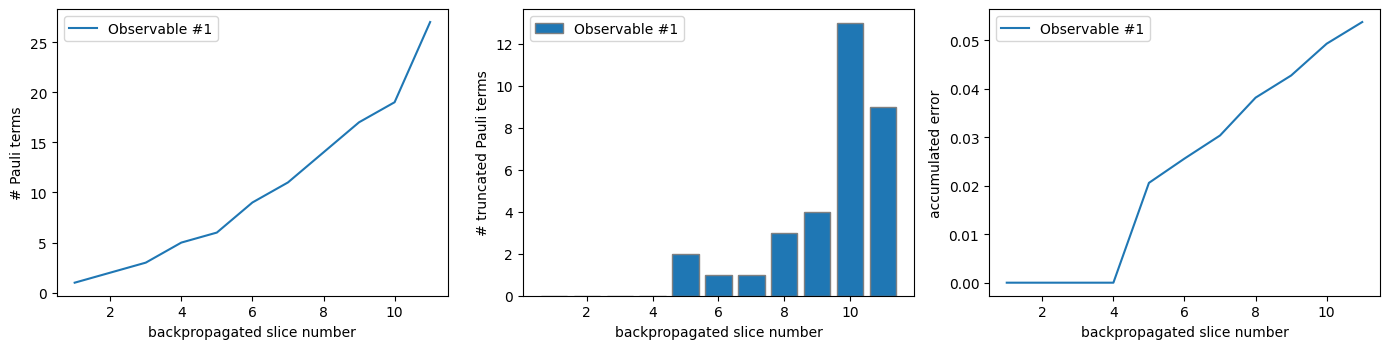

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
obp_vis.plot_num_paulis(metadata_trunc, axes[0])
obp_vis.plot_num_truncated_paulis(metadata_trunc, axes[1])
obp_vis.plot_accumulated_error(metadata_trunc, axes[2])
fig.tight_layout()
plt.show()

## 6. Evaluating the reduced experiments

We have three experiments: original, backpropagated, and backpropagated with truncation. As in the tutorial, we transpile them
for a fake 14-qubit backend. `apply_layout` maps the observables onto the physical layout. The noiseless `StatevectorEstimator`
then evaluates them.

The error budget gives a **certified interval**: the true value lies in $\langle\tilde O\rangle \pm$ `accumulated_error`.

In [12]:
from qiskit_ibm_runtime.fake_provider import FakeMelbourneV2

backend = FakeMelbourneV2()
pm = generate_preset_pass_manager(backend=backend, optimization_level=1, seed_transpiler=7)

def isa_pub(circ, obs):
    circ = circ if circ is not None else QuantumCircuit(N)   # all slices absorbed -> empty circuit
    isa = pm.run(circ)
    return isa, obs.apply_layout(isa.layout)

def two_q_depth(isa):
    return isa.depth(lambda x: x.operation.num_qubits == 2)

experiments = {
    "original": isa_pub(circuit, observable),
    "OBP (no truncation)": isa_pub(bp_circuit, bp_obs),
    "OBP + truncation 5e-3": isa_pub(bp_circuit_trunc, bp_obs_trunc),
}
bounds = {"original": 0.0, "OBP (no truncation)": metadata.accumulated_error(0),
          "OBP + truncation 5e-3": metadata_trunc.accumulated_error(0)}

estimator = StatevectorEstimator()
results = estimator.run(list(experiments.values())).result()

print(f"{'experiment':24s} {'#CX':>4s} {'2q depth':>8s} {'#QWC':>5s} {'<O>':>12s} {'|error|':>10s} {'bound':>10s}")
for (name, (isa, obs)), res in zip(experiments.items(), results):
    ev = float(res.data.evs)
    print(f"{name:24s} {isa.count_ops().get('cx', 0):4d} {two_q_depth(isa):8d} "
          f"{len(obs.group_commuting(qubit_wise=True)):5d} {ev:12.8f} {abs(ev - exact):10.2e} {bounds[name]:10.2e}")

experiment                #CX 2q depth  #QWC          <O>    |error|      bound
original                  108       24     1   0.88541607   1.55e-15   0.00e+00
OBP (no truncation)        70       16     8   0.88541607   1.11e-15   0.00e+00
OBP + truncation 5e-3      54       12     8   0.88502366   3.92e-04   4.93e-02


* Without truncation, OBP is **exact**. The error is at the level of floating-point rounding, and the CX count drops by about one third.
* With truncation, the error is about $4\times10^{-4}$. This is well inside the bound of about $5\times10^{-2}$. The bound is **rigorous
  but pessimistic**. It assumes that each truncated Pauli has $|\langle P\rangle|=1$ with the same sign. In practice, the
  truncated terms partly cancel.

## 7. Sweep: error budget vs. depth reduction vs. accuracy

We repeat the backpropagation for a range of budgets per slice, with the same `OperatorBudget(max_qwc_groups=8)`. For each run we record:

* the number of absorbed slices;
* the 2-qubit depth and the CX count of the transpiled remaining circuit;
* the size of the observable;
* the error bound and the actual error from the statevector.

Budget `0.0` means no truncation (we pass `None`).

In [13]:
budgets = [0.0, 1e-4, 5e-4, 1e-3, 2e-3, 5e-3, 1e-2, 2e-2, 5e-2]
orig_isa = experiments["original"][0]
rows = []
for eps in budgets:
    tb = setup_budget(max_error_per_slice=float(eps)) if eps > 0 else None
    o, rem, md_ = backpropagate(observable, slices, operator_budget=op_budget, truncation_error_budget=tb)
    isa, o_isa = isa_pub(combine_slices(rem), o)
    ev = float(estimator.run([(isa, o_isa)]).result()[0].data.evs)
    rows.append(dict(eps=eps, nbp=md_.num_backpropagated_slices, cx=isa.count_ops().get("cx", 0),
                     d2=two_q_depth(isa), nterms=len(o), nqwc=len(o.group_commuting(qubit_wise=True)),
                     ev=ev, err=abs(ev - exact), bound=md_.accumulated_error(0)))

print(f"original: CX={orig_isa.count_ops()['cx']}, 2q depth={two_q_depth(orig_isa)}\n")
print(f"{'eps/slice':>9s} {'slices':>6s} {'#CX':>4s} {'2q d':>5s} {'terms':>5s} {'QWC':>4s} {'<O>':>10s} {'|err|':>9s} {'bound':>9s}")
for r in rows:
    print(f"{r['eps']:9.0e} {r['nbp']:6d} {r['cx']:4d} {r['d2']:5d} {r['nterms']:5d} {r['nqwc']:4d} "
          f"{r['ev']:10.6f} {r['err']:9.2e} {r['bound']:9.2e}")

original: CX=108, 2q depth=24

eps/slice slices  #CX  2q d terms  QWC        <O>     |err|     bound
    0e+00      7   70    16    18    8   0.885416  2.22e-16  0.00e+00
    1e-04      7   70    16    18    8   0.885416  2.22e-16  0.00e+00
    5e-04      7   70    16    16    8   0.885560  1.44e-04  3.11e-03
    1e-03      7   70    16    15    8   0.886555  1.14e-03  6.57e-03
    2e-03      7   70    16    14    8   0.886962  1.55e-03  1.01e-02
    5e-03     10   54    12    19    8   0.885024  3.92e-04  4.93e-02
    1e-02     10   54    12    14    8   0.878844  6.57e-03  9.58e-02
    2e-02     16   16     4    12    8   0.862999  2.24e-02  3.09e-01
    5e-02     18    0     0     3    3   0.855726  2.97e-02  8.53e-01


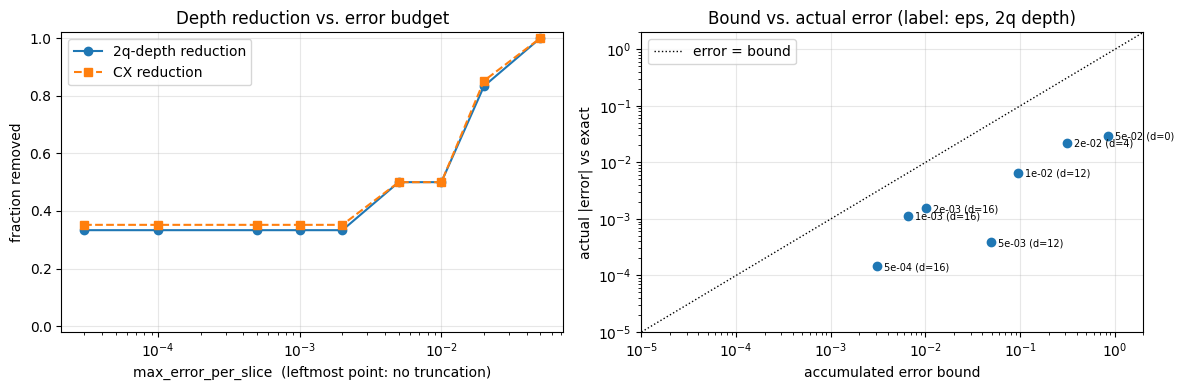

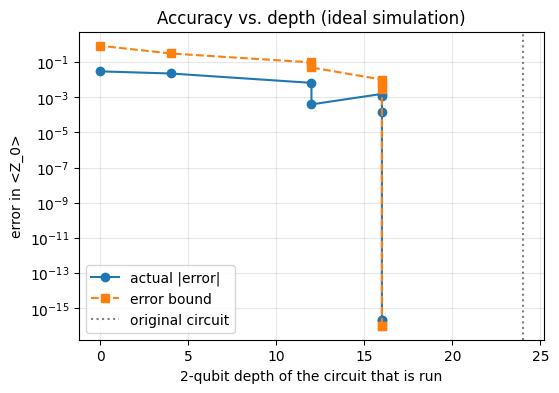

In [14]:
eps_arr = np.array([r["eps"] for r in rows])
d2 = np.array([r["d2"] for r in rows]); err = np.array([r["err"] for r in rows]); bnd = np.array([r["bound"] for r in rows])
x = np.where(eps_arr > 0, eps_arr, 3e-5)   # put "no truncation" on the log axis at the left
floor = 1e-16

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.semilogx(x, 1 - d2 / two_q_depth(orig_isa), "o-", label="2q-depth reduction")
ax.semilogx(x, 1 - np.array([r["cx"] for r in rows]) / orig_isa.count_ops()["cx"], "s--", label="CX reduction")
ax.set_xlabel("max_error_per_slice  (leftmost point: no truncation)"); ax.set_ylabel("fraction removed")
ax.set_ylim(-0.02, 1.02); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Depth reduction vs. error budget")

ax = axes[1]
m = bnd > 0   # runs that actually truncated (the others are exact to ~1e-16)
ax.loglog(bnd[m], err[m], "o")
for r, b, e in zip([r for r, k in zip(rows, m) if k], bnd[m], err[m]):
    ax.annotate(f"{r['eps']:.0e} (d={r['d2']})", (b, e), fontsize=7, textcoords="offset points", xytext=(5, -3))
lim = [1e-5, 2]
ax.plot(lim, lim, "k:", lw=1, label="error = bound")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("accumulated error bound"); ax.set_ylabel("actual |error| vs exact")
ax.set_title("Bound vs. actual error (label: eps, 2q depth)"); ax.legend(loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(d2, np.maximum(err, floor), "o-", label="actual |error|")
ax.semilogy(d2, np.maximum(bnd, floor), "s--", label="error bound")
ax.axvline(two_q_depth(orig_isa), color="gray", ls=":", label="original circuit")
ax.set_xlabel("2-qubit depth of the circuit that is run"); ax.set_ylabel("error in <Z_0>")
ax.set_title("Accuracy vs. depth (ideal simulation)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Results of the sweep.**

* Small budgets ($\lesssim 10^{-4}$) change nothing. The same 7 slices are absorbed, and the result is exact.
* Budgets of $5\times10^{-4}$–$2\times10^{-3}$ remove some terms, but not enough to fit an 8th slice into 8 QWC groups. They add error ($10^{-4}$–$10^{-3}$) and do not reduce the depth. The depth drops only in **steps**.
* At $5\times10^{-3}$–$10^{-2}$, OBP absorbs 10 slices. The error does not increase monotonically with the budget: at $5\times10^{-3}$ it is only $4\times10^{-4}$.
* Large budgets absorb **almost all or all** of the circuit. At $5\times10^{-2}$, *every* slice is absorbed. The circuit is empty, and the
  result is $\langle 0|\tilde O|0\rangle$, so no quantum computer is needed. Its error, about $3\times10^{-2}$, is the largest of the sweep.
  The bound is about $0.85$.
* The bound is always above the actual error. In the right panel, which shows only the runs with truncation, all points lie below the diagonal.
* The budget sets the balance between **depth**, which determines the hardware noise, and **classical bias**, which is bounded. With noise,
  choose the budget that gives the smallest total error, that is, noise plus truncation (Section 9).

### Spreading a total budget evenly

Instead of a budget per slice, we can fix the **total**. `setup_budget(max_error_total=E, num_slices=n)` spends at most $E/n$ per slice
(plus the carry-over) and never more than $E$ in total. Without `num_slices`, the first slice can use all of $E$, and it spends the budget greedily.

In [15]:
for kw in [dict(max_error_total=0.02, num_slices=len(slices)), dict(max_error_total=0.02)]:
    tb = setup_budget(**kw)
    o, rem, md_ = backpropagate(observable, slices, operator_budget=op_budget, truncation_error_budget=tb)
    isa, o_isa = isa_pub(combine_slices(rem), o)
    ev = float(estimator.run([(isa, o_isa)]).result()[0].data.evs)
    print(f"{str(kw):45s} slices={md_.num_backpropagated_slices:2d}  2q depth={two_q_depth(isa):2d}  "
          f"|err|={abs(ev-exact):.2e}  bound={md_.accumulated_error(0):.2e}  (<= {tb.max_error_total})")

{'max_error_total': 0.02, 'num_slices': 18}   slices= 7  2q depth=16  |err|=5.51e-04  bound=6.60e-03  (<= 0.02)
{'max_error_total': 0.02}                     slices= 7  2q depth=16  |err|=3.14e-03  bound=1.96e-02  (<= 0.02)


## 8. The operator budget trade-off

The second parameter is the maximum size of the observable. Each QWC group is a separate measurement setting. `max_qwc_groups` is
therefore approximately the factor on the number of circuits or shots. Without truncation, a larger budget absorbs more slices
exactly. The observable grows exponentially with the number of absorbed slices, so each additional slice costs more.

max_qwc slices  terms  QWC 2q depth time [s]
      1      1      1    1       24     0.01
      2      2      2    2       24     0.01
      4      4      5    3       22     0.01
      8      7     18    8       16     0.02
     16      9     39   12       12     0.02
     32     13     95   27       10     0.05
     64     15    207   54        6     0.09
    128     17    543  126        2     0.30


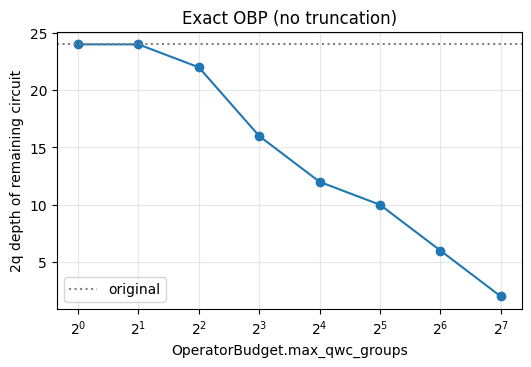

In [16]:
qwc_budgets = [1, 2, 4, 8, 16, 32, 64, 128]
res_q = []
for q in qwc_budgets:
    t0 = time.perf_counter()
    o, rem, md_ = backpropagate(observable, slices, operator_budget=OperatorBudget(max_qwc_groups=q))
    isa, _ = isa_pub(combine_slices(rem), o)
    res_q.append((q, md_.num_backpropagated_slices, len(o), len(o.group_commuting(qubit_wise=True)),
                  two_q_depth(isa), time.perf_counter() - t0))
print(f"{'max_qwc':>7s} {'slices':>6s} {'terms':>6s} {'QWC':>4s} {'2q depth':>8s} {'time [s]':>8s}")
for r in res_q:
    print(f"{r[0]:7d} {r[1]:6d} {r[2]:6d} {r[3]:4d} {r[4]:8d} {r[5]:8.2f}")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogx([r[0] for r in res_q], [r[4] for r in res_q], "o-", base=2)
ax.axhline(two_q_depth(orig_isa), color="gray", ls=":", label="original")
ax.set_xlabel("OperatorBudget.max_qwc_groups"); ax.set_ylabel("2q depth of remaining circuit")
ax.set_title("Exact OBP (no truncation)"); ax.grid(alpha=0.3); ax.legend()
plt.show()

## 9. Noisy simulation with Aer and a fake backend

In a noiseless simulation, OBP can only add error. Its benefit appears **with noise**. Here we run the same experiments with
the noise model of `FakeMelbourneV2` in a density-matrix `AerSimulator`, on the GPU if one is available. Aer removes idle qubits,
so it simulates only the 10 active qubits.

We use the Aer `EstimatorV2` with `default_precision=0`. It returns exact noisy expectation values without shot noise.
The comparison is then not affected by sampling noise.

The truncation bound still holds for the *noiseless* value of the reduced circuit. Hardware noise is an additional, separate error.

In [17]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.primitives import EstimatorV2 as AerEstimator

device = "GPU" if "GPU" in AerSimulator().available_devices() else "CPU"
noise_model = NoiseModel.from_backend(backend)
noisy_estimator = AerEstimator(options={
    "backend_options": {"method": "density_matrix", "device": device,
                        "noise_model": noise_model, "max_parallel_threads": 2},
    "default_precision": 0.0,
})
print("Aer device:", device)

noisy_cases = [("original", None, None)] + [(f"OBP eps={e:.0e}" if e else "OBP no trunc", e, None)
                                             for e in [0.0, 1e-3, 5e-3, 1e-2, 2e-2]]
pubs, info = [], []
for name, eps, _ in noisy_cases:
    if name == "original":
        isa, o_isa = experiments["original"]; bound = 0.0; nq = 1
    else:
        tb = setup_budget(max_error_per_slice=float(eps)) if eps else None
        o, rem, md_ = backpropagate(observable, slices, operator_budget=op_budget, truncation_error_budget=tb)
        isa, o_isa = isa_pub(combine_slices(rem), o)
        bound = md_.accumulated_error(0); nq = len(o.group_commuting(qubit_wise=True))
    pubs.append((isa, o_isa)); info.append((name, isa.count_ops().get("cx", 0), two_q_depth(isa), nq, bound))

t0 = time.perf_counter()
noisy_res = noisy_estimator.run(pubs).result()
ideal_res = estimator.run(pubs).result()
print(f"noisy simulation of {len(pubs)} PUBs took {time.perf_counter() - t0:.2f} s\n")

print(f"{'experiment':16s} {'#CX':>4s} {'2q d':>5s} {'QWC':>4s} {'ideal':>9s} {'noisy':>9s} {'|noisy-exact|':>13s} {'bound':>8s}")
noisy_err = []
for (name, cx, d, nq, bound), rn, ri in zip(info, noisy_res, ideal_res):
    vn, vi = float(rn.data.evs), float(ri.data.evs)
    noisy_err.append(abs(vn - exact))
    print(f"{name:16s} {cx:4d} {d:5d} {nq:4d} {vi:9.5f} {vn:9.5f} {abs(vn - exact):13.4f} {bound:8.1e}")

Aer device: GPU


noisy simulation of 6 PUBs took 1.40 s

experiment        #CX  2q d  QWC     ideal     noisy |noisy-exact|    bound
original          108    24    1   0.88542   0.72441        0.1610  0.0e+00
OBP no trunc       70    16    8   0.88542   0.66382        0.2216  0.0e+00
OBP eps=1e-03      70    16    8   0.88655   0.66483        0.2206  6.6e-03
OBP eps=5e-03      54    12    8   0.88502   0.79557        0.0898  4.9e-02
OBP eps=1e-02      54    12    8   0.87884   0.79063        0.0948  9.6e-02
OBP eps=2e-02      16     4    8   0.86300   0.86139        0.0240  3.1e-01


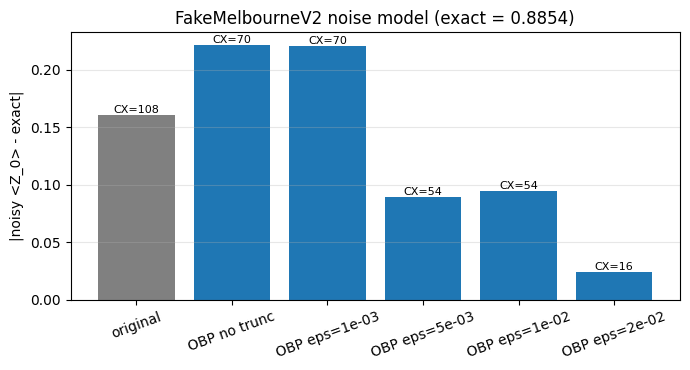

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.8))
names = [i[0] for i in info]
ax.bar(names, noisy_err, color=["gray"] + ["C0"] * (len(names) - 1))
for k, i in enumerate(info):
    ax.text(k, noisy_err[k], f"CX={i[1]}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("|noisy <Z_0> - exact|"); ax.set_title(f"FakeMelbourneV2 noise model (exact = {exact:.4f})")
plt.xticks(rotation=20); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation.** Fewer CX gates do **not** always give a better noisy result. The backpropagated observable is a sum of
*higher-weight* Paulis, such as $X_1X_0$ and $Z_2Y_1X_0$. With depolarizing and readout noise, the expectation value of a weight-$w$ Pauli
decays approximately as $(1-p)^w$. An exact OBP with only a moderate depth reduction can therefore give a *worse* result than the
original circuit.

When truncation removes most of the circuit, the reduction in noise is larger than both effects, and the noisy result is much closer
to the exact value. Choose the budgets by the **total** error: noise (which depends on depth and observable weight) plus truncation
(which is bounded). OBP also works well together with error-mitigation methods such as readout mitigation, zero-noise extrapolation
(ZNE) and probabilistic error cancellation (PEC). All of them become cheaper and more accurate on shallower circuits.

## 10. Summary, notes and references

* **Method:** in the Heisenberg picture, the observable evolves backwards. OBP absorbs the last slices of the circuit into the observable
  on a classical computer, $O\to U_L^\dagger O U_L\to\cdots$, and the device runs a shallower circuit. Without truncation, the result is exact.
* **Workflow:** `generate_xyz_hamiltonian` → `generate_time_evolution_circuit` → `slice_by_gate_types` →
  `backpropagate(obs, slices, operator_budget=OperatorBudget(max_qwc_groups=...), truncation_error_budget=setup_budget(...))` →
  `combine_slices(remaining)` → transpile, `apply_layout`, Estimator → report `ev ± metadata.accumulated_error(i)`.
* **Parameters:** `OperatorBudget` (`max_paulis`, `max_qwc_groups`) sets the measurement cost. `setup_budget` (`max_error_per_slice`,
  `max_error_total`, `num_slices`, `p_norm`) sets the bias. `max_seconds` adds a limit on the wall-clock time (not available on Windows).
* **This 10-qubit example:** exact OBP removes 7 of 18 slices. A budget of $5\times10^{-3}$ per slice removes 10 slices, with an actual error of
  about $4\times10^{-4}$. Large budgets absorb the whole circuit.

**Notes on the installed version (qiskit-addon-obp 0.3.0, qiskit-addon-utils 0.4.0)**

* `backpropagate` returns the observable in the same form as the input (one `SparsePauliOp`, or a list). `metadata.accumulated_error(i)` always needs the observable index `i`.
* `setup_budget(max_error_per_slice=1)` with an **int** raises `TypeError: 'int' object is not iterable`. Only a `float` counts as a scalar.
  Pass a float such as `1.0`, or a list.
* When all slices are absorbed, `combine_slices([])` returns **`None`**, not an empty circuit. Use `QuantumCircuit(N)` instead before transpiling.
* `metadata.backpropagation_history` contains the **rejected** last slice. Its last entry can therefore exceed the operator budget.
* The L1 error bound (`accumulated_error`) is strict. In this notebook it is about 5 to 130 times larger than the actual error.
* `slice_by_gate_types` can put adjacent slices that share no qubits in any order. This has no effect on the results here.

**References** (documentation pages)

1. Tutorial, Reducing depth of circuits with operator backpropagation: <https://qiskit.github.io/qiskit-addon-obp/tutorials/01_getting_started.html>
2. How-to, Truncating Pauli terms during backpropagation: <https://qiskit.github.io/qiskit-addon-obp/how_tos/truncate_operator_terms.html>
3. How-to, Using different Lp-norms for Pauli term truncation: <https://qiskit.github.io/qiskit-addon-obp/how_tos/bound_error_using_p_norm.html>
4. API reference, `qiskit_addon_obp` (`backpropagate`): <https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.html>
5. API reference, `qiskit_addon_obp.utils.simplify` (`OperatorBudget`): <https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.utils.simplify.html>
6. API reference, `qiskit_addon_obp.utils.truncating` (`setup_budget`): <https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.utils.truncating.html>
7. API reference, `qiskit_addon_obp.utils.metadata` (`OBPMetadata`): <https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.utils.metadata.html>
8. API reference, `qiskit_addon_obp.utils.visualization`: <https://qiskit.github.io/qiskit-addon-obp/apidocs/qiskit_addon_obp.utils.visualization.html>
9. IBM Quantum documentation, Operator backpropagation: <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-addon-obp>
10. IBM Quantum documentation, Operator backpropagation quick start: <https://quantum.cloud.ibm.com/docs/en/addons/qiskit-addon-obp/guides/quickstart>
11. API reference, `qiskit_addon_utils.problem_generators`: <https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.problem_generators.html>
12. API reference, `qiskit_addon_utils.slicing`: <https://qiskit.github.io/qiskit-addon-utils/apidocs/qiskit_addon_utils.slicing.html>